# Kinase Cross-Tree Analysis

Cross-tree comparison of evolutionary distance (Manning kinome tree, 2002) vs. substrate selectivity distance (yeast overexpression screening tree).

**Pipeline**
1. Parse both Newick trees and compute all pairwise branch-length distances
2. Normalise distances within each tree to \[0, 1\]
3. Map screening-tree leaf names to kinome-tree leaf names
4. Classify every mappable pair into one of four categories using median-based thresholds
5. Compute Pearson *r*, Spearman *ρ*, and Kendall *τ* between the two distance vectors
6. Visualise the relationship with a scatter plot

**Dependencies:** `ete3`, `scipy`, `numpy`, `pandas`, `matplotlib`, `seaborn`

## 0 · Imports

In [5]:
import re
import statistics
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from ete3 import Tree
from scipy import stats

## 1 · Configuration

In [6]:
# ── File paths ────────────────────────────────────────────────────────────────
KINOME_TREE  = "Human-PK-tree_newick.txt"
SCREEN_TREE  = "screening_tree_reordered_renamed_newick.nwk"

# ── Thresholds ────────────────────────────────────────────────────────────────
# Set to None to use the median of each distance vector (recommended).
# Override with a float to fix a specific cutoff, e.g. KINOME_THRESHOLD = 0.917
KINOME_THRESHOLD = None   # 'kinome close'  if normalised dist < threshold
SCREEN_THRESHOLD = None   # 'screen close'  if normalised dist < threshold

# ── Name mapping: screening tree leaf → kinome tree leaf ─────────────────────
# Mutant labels (T252D, T210D) and ambiguous entries (JAK2 - 1) are excluded.
# ADCK1 and PIM1 have no reliable kinome mapping and are excluded.
SCREEN_TO_KINOME = {
    "FES"   : "TYR_FES",
    "KSYK"  : "TYR_SYK",
    "TNK1"  : "TYR_TNK1",
    "FRK"   : "TYR_FRK",
    "FYN"   : "TYR_FYN",
    "ABL2"  : "TYR_ABL2",
    "STYK1" : "TYR_STYK1",
    "M3K7"  : "TKL_MAP3K7",
    "KGP1"  : "AGC_PRKG1",
    "PHKG1" : "CAMK_PHKG1",
    "KKCC1" : "CAMK_CAMKK1",
    "KS6B1" : "AGC_RPS6KB1",
    "PLK1"  : "CAMK_PLK1",
    "TBK1"  : "OTHER_TBK1",
    "PDPK1" : "AGC_PDPK1",
    "IKKB"  : "OTHER_IKBKB",
    "MAST1" : "AGC_MAST1",
    "TITIN" : "CAMK_TTN",
}

## 2 · Tree parsing utilities

In [7]:
def load_tree(newick_path: str) -> Tree:
    """
    Load a Newick tree, stripping the bracket bootstrap annotations used by
    the Manning kinome tree  (e.g. ):0.04050500[0.9864]) before parsing.
    Falls back across ETE3 format codes until one succeeds.
    """
    with open(newick_path) as fh:
        raw = fh.read()
    clean = re.sub(r"\[\d+\.\d+\]", "", raw)   # strip [bootstrap] annotations
    for fmt in (0, 1, 3):
        try:
            return Tree(clean, format=fmt)
        except Exception:
            continue
    raise ValueError(f"Could not parse tree: {newick_path}")


def get_normalised_distances(newick_path: str) -> tuple[dict, float, list]:
    """
    Parse a Newick tree and return all pairwise distances normalised to [0, 1].

    Returns
    -------
    norm_dists : dict   {(leaf_a, leaf_b): float}  — both orderings stored
    max_dist   : float  — raw maximum used for normalisation
    leaves     : list[str]
    """
    t = load_tree(newick_path)
    leaves = [leaf.name for leaf in t.get_leaves()]

    raw = {}
    for a, b in combinations(leaves, 2):
        dist = t.get_distance(a, b)
        raw[(a, b)] = dist
        raw[(b, a)] = dist

    max_dist = max(raw.values())
    norm = {pair: val / max_dist for pair, val in raw.items()}
    return norm, max_dist, leaves

## 3 · Load trees and compute pairwise distances

In [8]:
print("Parsing screening tree …")
screen_dists, screen_max, screen_leaves = get_normalised_distances(SCREEN_TREE)
print(f"  {len(screen_leaves)} leaves   max raw distance = {screen_max:.4f}")

print("Parsing kinome tree …")
kinome_dists, kinome_max, kinome_leaves = get_normalised_distances(KINOME_TREE)
print(f"  {len(kinome_leaves)} leaves   max raw distance = {kinome_max:.4f}")

Parsing screening tree …
  23 leaves   max raw distance = 2.0000
Parsing kinome tree …
  496 leaves   max raw distance = 0.9288


## 4 · Build the paired distance table

In [9]:
# Canonical screening leaves = those with a kinome mapping that are present in the tree
canonical = [s for s in SCREEN_TO_KINOME if s in screen_leaves]

excluded = [
    s for s in screen_leaves
    if s not in SCREEN_TO_KINOME
    and s not in ("KS6B1 T252D", "PLK1 T210D", "JAK2 - 1")
]

print(f"Canonical leaves with kinome mapping : {len(canonical)}")
print(f"  {sorted(canonical)}")
if excluded:
    print(f"\nExcluded (no kinome mapping) : {excluded}")

# Build paired list
rows = []
for a, b in combinations(sorted(canonical), 2):
    sd = screen_dists.get((a, b))
    kd = kinome_dists.get((SCREEN_TO_KINOME[a], SCREEN_TO_KINOME[b]))
    if sd is not None and kd is not None:
        rows.append({"kinase_a": a, "kinase_b": b,
                     "screen_dist": sd, "kinome_dist": kd})

df = pd.DataFrame(rows)
print(f"\nMappable pairs : {len(df)}")
df.head(10)

Canonical leaves with kinome mapping : 18
  ['ABL2', 'FES', 'FRK', 'FYN', 'IKKB', 'KGP1', 'KKCC1', 'KS6B1', 'KSYK', 'M3K7', 'MAST1', 'PDPK1', 'PHKG1', 'PLK1', 'STYK1', 'TBK1', 'TITIN', 'TNK1']

Excluded (no kinome mapping) : ['ADCK1', 'PIM1']

Mappable pairs : 153


,kinase_a,kinase_b,screen_dist,kinome_dist
0,ABL2,FES,0.567864,0.639003
1,ABL2,FRK,0.567864,0.600271
2,ABL2,FYN,0.567864,0.589628
3,ABL2,IKKB,1.000000,0.825251
4,ABL2,KGP1,1.000000,0.822501
5,ABL2,KKCC1,1.000000,0.822215
6,ABL2,KS6B1,1.000000,0.800875
7,ABL2,KSYK,0.567864,0.677167
8,ABL2,M3K7,1.000000,0.784382
9,ABL2,MAST1,1.000000,0.815967


## 5 · Set thresholds and classify pairs

In [21]:
df["kinome_dist"].max()

np.float64(0.8756430603319257)

In [23]:
statistics.mean(df["screen_dist"])

0.8990944509624182

In [24]:
# Use medians if no override was supplied
k_thresh = KINOME_THRESHOLD if KINOME_THRESHOLD is not None \
           else float(statistics.mean(df["kinome_dist"]))
s_thresh = SCREEN_THRESHOLD if SCREEN_THRESHOLD is not None \
           else float(statistics.mean(df["screen_dist"]))

print(f"Kinome threshold : {k_thresh:.4f}  ('close' = normalised dist < {k_thresh:.4f})")
print(f"Screen threshold : {s_thresh:.4f}  ('close' = normalised dist < {s_thresh:.4f})")

# ── Classification ────────────────────────────────────────────────────────────
# Category logic (strict < for 'close'; pairs at the boundary go to 'far')
#
#  Conservation  : kinome close  AND  screen close
#  Divergence    : kinome close  AND  screen far      (functionally decoupled)
#  Convergence   : kinome far    AND  screen close     (independently similar)
#  Expected far  : kinome far    AND  screen far

def classify(row):
    kc = row["kinome_dist"] < k_thresh
    sc = row["screen_dist"] < s_thresh
    if   kc and     sc: return "Conservation"
    elif kc and not sc: return "Divergence"
    elif not kc and sc: return "Convergence"
    else:               return "Expected far"

df["category"] = df.apply(classify, axis=1)

print("\nCategory counts:")
print(df["category"].value_counts().to_string())

Kinome threshold : 0.7836  ('close' = normalised dist < 0.7836)
Screen threshold : 0.8991  ('close' = normalised dist < 0.8991)

Category counts:
category
Expected far    94
Conservation    35
Divergence      17
Convergence      7


## 6 · Per-category tables

In [25]:
CAT_ORDER = ["Conservation", "Divergence", "Convergence", "Expected far"]

for cat in CAT_ORDER:
    sub = (df[df["category"] == cat]
           .sort_values("screen_dist")[["kinase_a", "kinase_b", "screen_dist", "kinome_dist"]]
           .reset_index(drop=True))
    print(f"\n{'─'*60}")
    print(f"{cat}   (n = {len(sub)})")
    print(f"{'─'*60}")
    display(sub.style.format({"screen_dist": "{:.4f}", "kinome_dist": "{:.4f}"}))


────────────────────────────────────────────────────────────
Conservation   (n = 35)
────────────────────────────────────────────────────────────


,kinase_a,kinase_b,screen_dist,kinome_dist
0,FRK,TNK1,0.1542,0.6702
1,FRK,FYN,0.2069,0.4707
2,FYN,TNK1,0.2069,0.6596
3,FYN,KSYK,0.2653,0.6698
4,KSYK,TNK1,0.2653,0.6610
5,FRK,KSYK,0.2653,0.6805
6,FES,KSYK,0.3650,0.6759
7,FES,FRK,0.3650,0.6423
8,FES,TNK1,0.3650,0.6656
9,FES,FYN,0.3650,0.6317



────────────────────────────────────────────────────────────
Divergence   (n = 17)
────────────────────────────────────────────────────────────


,kinase_a,kinase_b,screen_dist,kinome_dist
0,IKKB,MAST1,0.9231,0.7808
1,KS6B1,M3K7,0.9496,0.7815
2,IKKB,PDPK1,0.9750,0.7800
3,IKKB,KS6B1,0.9750,0.7658
4,IKKB,PHKG1,0.9750,0.7661
5,IKKB,PLK1,0.9750,0.7721
6,IKKB,TBK1,0.9750,0.7376
7,IKKB,KKCC1,0.9750,0.7753
8,KS6B1,MAST1,0.9750,0.6408
9,MAST1,PDPK1,0.9750,0.6730



────────────────────────────────────────────────────────────
Convergence   (n = 7)
────────────────────────────────────────────────────────────


,kinase_a,kinase_b,screen_dist,kinome_dist
0,KGP1,KKCC1,0.8420,0.7843
1,PDPK1,TBK1,0.8773,0.8024
2,KKCC1,TBK1,0.8895,0.7977
3,KGP1,TBK1,0.8895,0.8098
4,KS6B1,TBK1,0.8895,0.7882
5,PHKG1,TBK1,0.8895,0.7886
6,PLK1,TBK1,0.8895,0.7946



────────────────────────────────────────────────────────────
Expected far   (n = 94)
────────────────────────────────────────────────────────────


,kinase_a,kinase_b,screen_dist,kinome_dist
0,KGP1,M3K7,0.9496,0.8031
1,KKCC1,M3K7,0.9496,0.8028
2,M3K7,PLK1,0.9496,0.7997
3,M3K7,PHKG1,0.9496,0.7937
4,M3K7,PDPK1,0.9496,0.7957
5,M3K7,TBK1,0.9496,0.8283
6,IKKB,KGP1,0.9750,0.7874
7,IKKB,M3K7,0.9750,0.8059
8,MAST1,TBK1,0.9750,0.8033
9,M3K7,MAST1,0.9750,0.7966


## 7 · Correlation statistics

In [26]:
sv = df["screen_dist"].values
kv = df["kinome_dist"].values
n  = len(df)

r,   r_p   = stats.pearsonr(sv, kv)
rho, rho_p = stats.spearmanr(sv, kv)
tau, tau_p = stats.kendalltau(sv, kv)

n_ceiling = int(np.sum(sv >= s_thresh))

corr_df = pd.DataFrame({
    "Statistic" : ["Pearson r", "Spearman ρ", "Kendall τ"],
    "Value"     : [r, rho, tau],
    "R²"        : [r**2, "", ""],
    "p-value"   : [r_p, rho_p, tau_p],
})

print(f"Descriptive statistics  (n = {n} pairs)")
print(f"  Screen : mean={sv.mean():.3f}  SD={sv.std(ddof=1):.3f}  "
      f"range=[{sv.min():.3f}, {sv.max():.3f}]")
print(f"  Kinome : mean={kv.mean():.3f}  SD={kv.std(ddof=1):.3f}  "
      f"range=[{kv.min():.3f}, {kv.max():.3f}]")
print(f"\n  Note: {n_ceiling}/{n} ({100*n_ceiling/n:.0f}%) screen distances are at "
      f"ceiling (≥ {s_thresh:.3f}).")
print("  Rank-based metrics (Spearman, Kendall) are preferred as primary "
      "effect sizes.\n")

display(corr_df.style.format({
    "Value"   : "{:.4f}",
    "R²"      : lambda x: f"{x:.4f}" if isinstance(x, float) else x,
    "p-value" : "{:.2e}",
}))

Descriptive statistics  (n = 153 pairs)
  Screen : mean=0.899  SD=0.196  range=[0.154, 1.000]
  Kinome : mean=0.784  SD=0.065  range=[0.471, 0.876]

  Note: 111/153 (73%) screen distances are at ceiling (≥ 0.899).
  Rank-based metrics (Spearman, Kendall) are preferred as primary effect sizes.



,Statistic,Value,R²,p-value
0,Pearson r,0.7802,0.6088,1.41e-32
1,Spearman ρ,0.8074,,2.01e-36
2,Kendall τ,0.6381,,2.86e-28


## 8 · Scatter plot

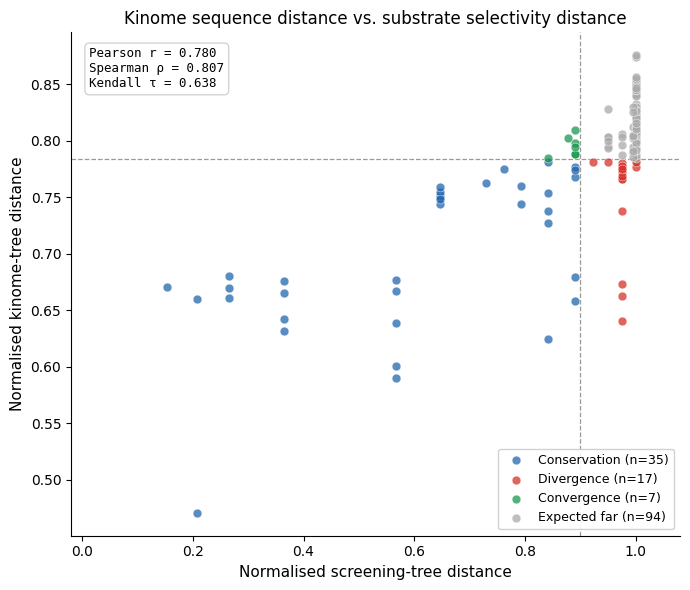

Figure saved → kinase_cross_tree_scatter.pdf


In [27]:
PALETTE = {
    "Conservation" : "#2166ac",   # blue
    "Divergence"   : "#d73027",   # red
    "Convergence"  : "#1a9850",   # green
    "Expected far" : "#aaaaaa",   # grey
}

fig, ax = plt.subplots(figsize=(7, 6))

for cat in CAT_ORDER:
    sub = df[df["category"] == cat]
    ax.scatter(
        sub["screen_dist"], sub["kinome_dist"],
        c=PALETTE[cat], label=f"{cat} (n={len(sub)})",
        s=40, alpha=0.75, edgecolors="white", linewidths=0.4, zorder=3,
    )

# Threshold lines
ax.axvline(s_thresh, color="#555555", lw=0.9, ls="--", alpha=0.6)
ax.axhline(k_thresh, color="#555555", lw=0.9, ls="--", alpha=0.6)

# Annotation: correlation stats
ax.text(
    0.03, 0.97,
    f"Pearson r = {r:.3f}\nSpearman ρ = {rho:.3f}\nKendall τ = {tau:.3f}",
    transform=ax.transAxes, va="top", ha="left",
    fontsize=9, family="monospace",
    bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="#cccccc", alpha=0.85),
)

ax.set_xlabel("Normalised screening-tree distance", fontsize=11)
ax.set_ylabel("Normalised kinome-tree distance", fontsize=11)
ax.set_title("Kinome sequence distance vs. substrate selectivity distance", fontsize=12)
ax.legend(loc="lower right", fontsize=9, framealpha=0.9)
ax.set_xlim(-0.02, 1.08)
sns.despine(ax=ax)

plt.tight_layout()
plt.savefig("kinase_cross_tree_scatter.pdf", dpi=200)
plt.show()
print("Figure saved → kinase_cross_tree_scatter.pdf")

## 9 · Export full results table

In [28]:
out = (
    df[["kinase_a", "kinase_b", "screen_dist", "kinome_dist", "category"]]
    .sort_values(["category", "screen_dist"])
    .reset_index(drop=True)
)
out.to_csv("kinase_cross_tree_results.csv", index=False)
print(f"Saved {len(out)} rows → kinase_cross_tree_results.csv")
display(out)

Saved 153 rows → kinase_cross_tree_results.csv


,kinase_a,kinase_b,screen_dist,kinome_dist,category
0,FRK,TNK1,0.154208,0.670206,Conservation
1,FRK,FYN,0.206878,0.470705,Conservation
2,FYN,TNK1,0.206878,0.659563,Conservation
3,FRK,KSYK,0.265306,0.680467,Conservation
4,FYN,KSYK,0.265306,0.669824,Conservation
...,...,...,...,...,...
148,PDPK1,STYK1,1.000000,0.841115,Expected far
149,PHKG1,STYK1,1.000000,0.839122,Expected far
150,PLK1,STYK1,1.000000,0.845110,Expected far
151,STYK1,TBK1,1.000000,0.873728,Expected far


In [29]:
out.loc[out['category']=='Divergence',:]

,kinase_a,kinase_b,screen_dist,kinome_dist,category
42,IKKB,MAST1,0.923077,0.780849,Divergence
43,KS6B1,M3K7,0.949640,0.781503,Divergence
44,IKKB,KKCC1,0.975000,0.775269,Divergence
45,IKKB,KS6B1,0.975000,0.765757,Divergence
46,IKKB,PDPK1,0.975000,0.779955,Divergence
47,IKKB,PHKG1,0.975000,0.766134,Divergence
48,IKKB,PLK1,0.975000,0.772121,Divergence
49,IKKB,TBK1,0.975000,0.737580,Divergence
50,KGP1,MAST1,0.975000,0.662399,Divergence
51,KKCC1,MAST1,0.975000,0.777813,Divergence
